# Parkinson's Dataset: Exploratory Data Analysis

This notebook is a **read-only** audit of the local multi-modal files. It inspects the labeled spiral/wave drawing images, handwriting sensor streams, and available gait/motion exports. It does not combine cohorts or train a model.

**Important scope:** the available labels appear to describe known healthy/control versus Parkinson's cases. That supports exploratory case-control analysis, not prospective early-risk prediction or clinical diagnosis. Diagnosis labels, file paths, subject IDs, task names, and medication state must not become model inputs.

In [1]:
from pathlib import Path
import hashlib
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Support execution from either the repository root or notebooks/.
_here = Path.cwd().resolve()
PROJECT_ROOT = next(
    (candidate for candidate in [_here, *_here.parents]
     if (candidate / "data" / "Parkinson's Datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find data/Parkinson's Datasets from the current directory")

DATA_ROOT = PROJECT_ROOT / "data" / "Parkinson's Datasets"
DRAWING_ROOT = DATA_ROOT / "Parkinson's drawings dataset" / "drawings"
HANDWRITING_ROOTS = [
    DATA_ROOT / "Park's UCI kaggle dataset" / "hw_dataset",
    DATA_ROOT / "Parkinson's UCI dataset" / "hw_dataset",
]

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.25})
print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset root exists: {DATA_ROOT.is_dir()}")
print("No source files are written or modified by this notebook.")

Project root: C:\Users\daisy\Projects\AI\pd-ml-lab
Dataset root exists: True
No source files are written or modified by this notebook.


## 1. What is in the repository?

**Reasoning:** these folders are distinct source cohorts and file formats, not one canonical table. Count files and storage by top-level dataset and extension before parsing anything. AppleDouble metadata files and notebook checkpoints are excluded from the data counts.

In [ ]:
def is_dataset_file(path):
    parts = {part.lower() for part in path.parts}
    return (
        path.is_file()
        and not path.name.startswith("._")
        and path.name.lower() != ".ds_store"
        and ".ipynb_checkpoints" not in parts
    )

all_files = [path for path in DATA_ROOT.rglob("*") if is_dataset_file(path)]
inventory = pd.DataFrame(
    {
        "dataset": [path.relative_to(DATA_ROOT).parts[0] for path in all_files],
        "extension": [path.suffix.lower() or "[no extension]" for path in all_files],
        "bytes": [path.stat().st_size for path in all_files],
    }
)
inventory_summary = (
    inventory.groupby(["dataset", "extension"], dropna=False)
    .agg(files=("bytes", "size"), total_mb=("bytes", lambda values: values.sum() / 1e6))
    .reset_index()
    .sort_values(["dataset", "files"], ascending=[True, False])
)
display(inventory_summary)
print(f"Total included files: {len(all_files):,}; total size: {inventory['bytes'].sum() / 1e9:.2f} GB")

## 2. Handwriting sensor streams: schema, types, missingness, and labels

**Reasoning:** the included readme declares seven semicolon-separated fields. Validate the raw row widths instead of silently coercing malformed rows; infer class only when it is explicitly present in a `control`/`parkinson` directory or the `C_`/`P_` filename prefix. A sensor row is not an independent person: keep the source file as the grouping unit, and do not treat `Test ID` as diagnosis.

In [12]:
sensor_columns = ["X", "Y", "Z", "Pressure", "GripAngle", "Timestamp", "Test ID"]
sensor_rows = []
sensor_file_audit = []

for source_root in HANDWRITING_ROOTS:
    if not source_root.exists():
        warnings.warn(f"Handwriting directory not found: {source_root}")
        continue
    release = source_root.relative_to(DATA_ROOT).parts[0]
    for path in sorted(source_root.rglob("*.txt")):
        if path.name.lower() == "readme.txt" or path.name.startswith("._"):
            continue
        parsed_rows = []
        malformed_lines = 0
        with path.open("r", encoding="utf-8-sig", errors="replace") as source:
            for line_number, line in enumerate(source, start=1):
                if not line.strip():
                    continue
                values = [value.strip() for value in line.strip().split(";")]
                if len(values) != len(sensor_columns):
                    malformed_lines += 1
                    continue
                parsed_rows.append(values)

        relative_path = path.relative_to(DATA_ROOT).as_posix()
        path_tokens = {part.lower() for part in path.parts}
        label = next((name for name in ("control", "healthy", "parkinson") if name in path_tokens), None)
        label_source = "directory" if label else "unlabeled"
        if label is None:
            prefix = path.stem.upper()
            if prefix.startswith("C_"):
                label, label_source = "control", "filename prefix"
            elif prefix.startswith("P_"):
                label, label_source = "parkinson", "filename prefix"

        sensor_file_audit.append({
            "release": release,
            "file": relative_path,
            "label": label,
            "label_source": label_source,
            "rows": len(parsed_rows),
            "malformed_nonblank_lines": malformed_lines,
        })
        for row_index, values in enumerate(parsed_rows):
            sensor_rows.append({
                "release": release,
                "file": relative_path,
                "row_index": row_index,
                "label": label,
                "label_source": label_source,
                **dict(zip(sensor_columns, values)),
            })

sensor_files = pd.DataFrame(sensor_file_audit)
sensors = pd.DataFrame(sensor_rows)
if sensors.empty:
    raise ValueError("No parseable handwriting sensor rows found under the configured dataset roots")
for column in sensor_columns:
    sensors[column] = pd.to_numeric(sensors[column], errors="coerce")

print(f"Parsed {len(sensor_files):,} files and {len(sensors):,} rows")
print("Declared schema, observed dtype, and missing values:")
schema_audit = pd.DataFrame({
    "dtype": sensors[sensor_columns].dtypes.astype(str),
    "missing_values": sensors[sensor_columns].isna().sum(),
    "missing_percent": sensors[sensor_columns].isna().mean().mul(100).round(2),
})
display(schema_audit)
print("Malformed nonblank line counts by file:")
display(sensor_files.loc[sensor_files["malformed_nonblank_lines"].gt(0)].head(20))
print("Rows per release and inferred label:")
display(sensors.groupby(["release", "label", "label_source"], dropna=False).size().rename("rows").reset_index())

Parsed 120 files and 968,907 rows
Declared schema, observed dtype, and missing values:


,dtype,missing_values,missing_percent
X,int64,0,0.0
Y,int64,0,0.0
Z,int64,0,0.0
Pressure,int64,0,0.0
GripAngle,int64,0,0.0
Timestamp,int64,0,0.0
Test ID,int64,0,0.0


Malformed nonblank line counts by file:


,release,file,label,label_source,rows,malformed_nonblank_lines


Rows per release and inferred label:


,release,label,label_source,rows
0,Park's UCI kaggle dataset,control,directory,120310
1,Park's UCI kaggle dataset,control,filename prefix,120310
2,Park's UCI kaggle dataset,parkinson,directory,202659
3,Park's UCI kaggle dataset,parkinson,filename prefix,202659
4,Parkinson's UCI dataset,control,directory,120310
5,Parkinson's UCI dataset,parkinson,directory,202659


### Class balance and task codes

**Reasoning:** labels need counts at both the file and row level. Row balance can be misleading when recordings have different lengths. The readme maps `Test ID` 0/1/2 to static spiral/dynamic spiral/circular motion; task identity is a design variable, not the clinical target.

In [ ]:
file_class_counts = sensor_files.groupby(["release", "label"], dropna=False).size().rename("files").reset_index()
row_class_counts = sensors.groupby(["release", "label"], dropna=False).size().rename("rows").reset_index()
print("Recording/file counts:")
display(file_class_counts)
print("Sample-row counts (not independent participants):")
display(row_class_counts)
print("Observed task IDs by release and inferred class:")
display(
    sensors.groupby(["release", "label", "Test ID"], dropna=False)
    .agg(rows=("row_index", "size"), files=("file", "nunique"))
    .reset_index()
)
print("Per-recording row-count summary:")
display(sensor_files.groupby(["release", "label"], dropna=False)["rows"].describe().round(1))

### Representative trajectories

**Reasoning:** a path plot reveals task differences, pauses, and unusual strokes that aggregate statistics hide. Samples are plotted against row index rather than assuming units or cadence for `Timestamp`; each selected view is one recording and one task.

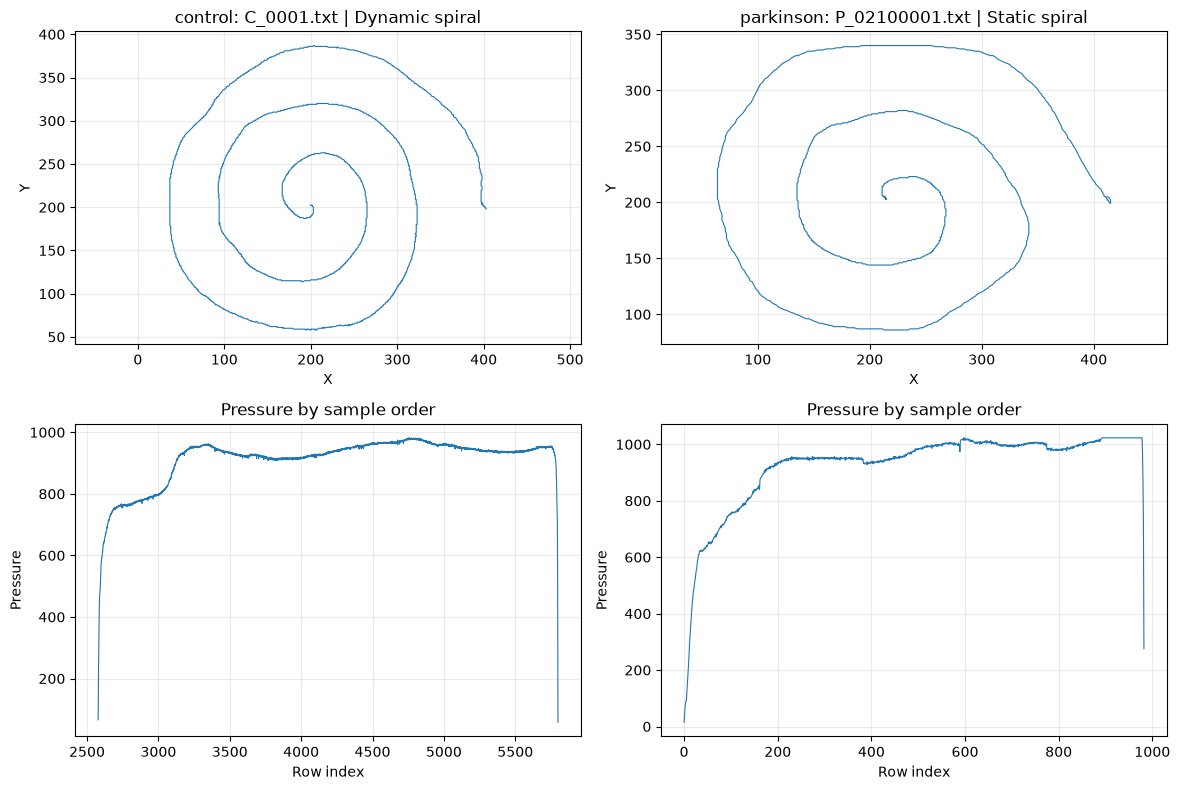

In [3]:
task_names = {0: "Static spiral", 1: "Dynamic spiral", 2: "Circular motion"}
releases_with_both_classes = (
    sensor_files.dropna(subset=["label"]).groupby("release")["label"].nunique()
)
selected_release = next((name for name, count in releases_with_both_classes.items() if count >= 2), None)
selected_files = {}
if selected_release is not None:
    subset = sensor_files[(sensor_files["release"] == selected_release) & sensor_files["label"].isin(["control", "parkinson"])]
    for class_name in ("control", "parkinson"):
        candidates = subset[subset["label"] == class_name].sort_values("file")
        if not candidates.empty:
            selected_files[class_name] = candidates.iloc[0]["file"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column_index, class_name in enumerate(("control", "parkinson")):
    relative_file = selected_files.get(class_name)
    if relative_file is None:
        axes[0, column_index].set_visible(False)
        axes[1, column_index].set_visible(False)
        continue
    record = sensors[sensors["file"] == relative_file].sort_values("row_index")
    task_id = int(record["Test ID"].mode().iloc[0])
    task_record = record[record["Test ID"] == task_id]
    axes[0, column_index].plot(task_record["X"], task_record["Y"], linewidth=0.8)
    axes[0, column_index].set_aspect("equal", adjustable="datalim")
    axes[0, column_index].set_title(f"{class_name}: {Path(relative_file).name} | {task_names.get(task_id, task_id)}")
    axes[0, column_index].set_xlabel("X")
    axes[0, column_index].set_ylabel("Y")
    axes[1, column_index].plot(task_record["row_index"], task_record["Pressure"], linewidth=0.8)
    axes[1, column_index].set_title("Pressure by sample order")
    axes[1, column_index].set_xlabel("Row index")
    axes[1, column_index].set_ylabel("Pressure")
fig.tight_layout()
plt.show()

In [14]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

release_contents = {}
for source_root in HANDWRITING_ROOTS:
    if not source_root.exists():
        continue
    release = source_root.relative_to(DATA_ROOT).parts[0]
    for path in source_root.rglob("*.txt"):
        if path.name.lower() == "readme.txt" or path.name.startswith("._"):
            continue
        if not any(part.lower() in {"control", "healthy", "parkinson"} for part in path.parts):
            if not path.stem.upper().startswith(("C_", "P_")):
                continue
        key = (path.name, sha256_file(path))
        release_contents.setdefault(key, set()).add(release)

shared_recordings = [
    {"filename": filename, "sha256": digest, "releases": sorted(releases)}
    for (filename, digest), releases in release_contents.items()
    if len(releases) > 1
]
print(f"Unique exact recording contents shared across releases: {len(shared_recordings):,}")
if shared_recordings:
    display(pd.DataFrame(shared_recordings).drop(columns="sha256").head(20))
print("Different directory nesting is allowed; matching requires both basename and exact SHA-256 content.")

Unique exact recording contents shared across releases: 40


,filename,releases
0,C_0001.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
1,C_0002.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
2,C_0003.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
3,C_0004.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
4,C_0005.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
5,C_0006.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
6,C_0007.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
7,C_0008.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
8,C_0009.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."
9,C_0010.txt,"[Park's UCI kaggle dataset, Parkinson's UCI da..."


Different directory nesting is allowed; matching requires both basename and exact SHA-256 content.


## 3. Labeled spiral and wave images

**Reasoning:** this is the clearest image classification subset because class and train/test are explicit in the directory tree. Preserve the supplied split for inspection, but verify exact-image duplication and provisional subject-token overlap; filenames and parent folders directly reveal the label and therefore cannot be passed as features.

In [6]:
image_records = []
if DRAWING_ROOT.exists():
    try:
        from PIL import Image
    except ImportError as error:
        warnings.warn(f"Pillow is unavailable; image EDA will be skipped: {error}")
        Image = None

    image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
    for path in sorted(DRAWING_ROOT.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in image_extensions:
            continue
        relative_parts = path.relative_to(DRAWING_ROOT).parts
        if len(relative_parts) < 3:
            continue
        task, split, label = relative_parts[:3]
        record = {
            "path": path,
            "task": task,
            "split": split,
            "label": label,
            "filename": path.name,
            "subject_token_candidate": re.search(r"V\d+", path.stem, flags=re.IGNORECASE).group(0).upper()
                if re.search(r"V\d+", path.stem, flags=re.IGNORECASE) else None,
            "sha256": sha256_file(path),
            "bytes": path.stat().st_size,
        }
        if Image is not None:
            with Image.open(path) as image:
                record.update({"width": image.width, "height": image.height, "mode": image.mode})
                pixels = np.asarray(image.convert("L"), dtype=np.float32) / 255.0
                record["pixel_mean"] = float(pixels.mean())
                record["pixel_std"] = float(pixels.std())
                record["dark_pixel_fraction"] = float((pixels < 0.65).mean())
        image_records.append(record)

images = pd.DataFrame(image_records)
if images.empty:
    print(f"No supported images found at {DRAWING_ROOT}")
else:
    print(f"Canonical image subset: {len(images):,} files")
    print("Class counts by task and supplied split:")
    display(images.groupby(["task", "split", "label"]).size().rename("images").reset_index())
    print("Observed file types, shapes, and pixel modes:")
    display(images.groupby(["task", "split", "label", "width", "height", "mode"], dropna=False).size().rename("images").reset_index())
    print("Image scalar summaries (descriptive only; not normalized across acquisition sources):")
    display(images.groupby(["task", "split", "label"])[["pixel_mean", "pixel_std", "dark_pixel_fraction"]].mean().round(3))

Canonical image subset: 204 files
Class counts by task and supplied split:


,task,split,label,images
0,spiral,testing,healthy,15
1,spiral,testing,parkinson,15
2,spiral,training,healthy,36
3,spiral,training,parkinson,36
4,wave,testing,healthy,15
5,wave,testing,parkinson,15
6,wave,training,healthy,36
7,wave,training,parkinson,36


Observed file types, shapes, and pixel modes:


,task,split,label,width,height,mode,images
0,spiral,testing,healthy,256,256,RGB,15
1,spiral,testing,parkinson,256,256,RGB,15
2,spiral,training,healthy,253,254,RGB,2
3,spiral,training,healthy,256,256,RGB,28
4,spiral,training,healthy,256,256,RGBA,5
...,...,...,...,...,...,...,...
88,wave,training,parkinson,512,393,RGB,1
89,wave,training,parkinson,512,445,RGB,1
90,wave,training,parkinson,512,455,RGB,1
91,wave,training,parkinson,512,492,RGB,1


Image scalar summaries (descriptive only; not normalized across acquisition sources):


pixel_mean  pixel_std  dark_pixel_fraction
task   split    label                                                
spiral testing  healthy         0.905      0.083                0.035
                parkinson       0.898      0.097                0.048
       training healthy         0.906      0.085                0.036
                parkinson       0.902      0.085                0.039
wave   testing  healthy         0.906      0.094                0.041
                parkinson       0.899      0.091                0.042
       training healthy         0.908      0.077                0.029
                parkinson       0.902      0.086                0.037

### Image leakage and split audit

**Reasoning:** an image-level split can leak if a participant contributed multiple drawings, or if the exact same image appears in both partitions. SHA-256 detects exact copies; a `V##` filename token is only a candidate grouping key until its meaning is confirmed from dataset documentation.

In [7]:
if not images.empty:
    duplicate_groups = (
        images.groupby("sha256")
        .agg(files=("filename", "size"), splits=("split", "nunique"), labels=("label", "nunique"), paths=("path", list))
        .query("files > 1")
    )
    cross_split_duplicates = duplicate_groups[duplicate_groups["splits"] > 1]
    print(f"Exact duplicate-image hash groups within this subset: {len(duplicate_groups)}")
    print(f"Exact duplicate-image groups spanning train/test: {len(cross_split_duplicates)}")
    if not cross_split_duplicates.empty:
        display(cross_split_duplicates[["files", "splits", "labels"]])

    token_sets = (
        images.dropna(subset=["subject_token_candidate"])
        .groupby(["task", "label", "split"])["subject_token_candidate"]
        .apply(set)
        .to_dict()
    )
    token_overlap = []
    for task in sorted(images["task"].unique()):
        for label in sorted(images["label"].unique()):
            train_tokens = token_sets.get((task, label, "training"), set())
            test_tokens = token_sets.get((task, label, "testing"), set())
            token_overlap.append({
                "task": task,
                "label": label,
                "train_candidate_tokens": len(train_tokens),
                "test_candidate_tokens": len(test_tokens),
                "overlap_tokens": sorted(train_tokens & test_tokens),
            })
    display(pd.DataFrame(token_overlap))
    print("Interpret candidate-token overlap as a prompt to verify participant IDs, not as a definitive identity result.")

Exact duplicate-image hash groups within this subset: 0
Exact duplicate-image groups spanning train/test: 0


,task,label,train_candidate_tokens,test_candidate_tokens,overlap_tokens
0,spiral,healthy,13,12,"[V01, V02, V03, V04, V05, V06, V07, V08, V09, ..."
1,spiral,parkinson,15,13,"[V01, V02, V03, V04, V05, V06, V07, V08, V09, ..."
2,wave,healthy,13,12,"[V01, V02, V03, V04, V05, V06, V07, V08, V09, ..."
3,wave,parkinson,15,12,"[V01, V02, V03, V04, V05, V06, V07, V08, V09, ..."


Interpret candidate-token overlap as a prompt to verify participant IDs, not as a definitive identity result.


### Visualize the drawings and coarse image statistics

**Reasoning:** first inspect examples and basic image variability, then compare descriptive darkness statistics by task, split, and class. Brightness can reflect paper/background, scanning, contrast, and preprocessing as much as motor symptoms, so these plots are diagnostics, not evidence of clinical separation.

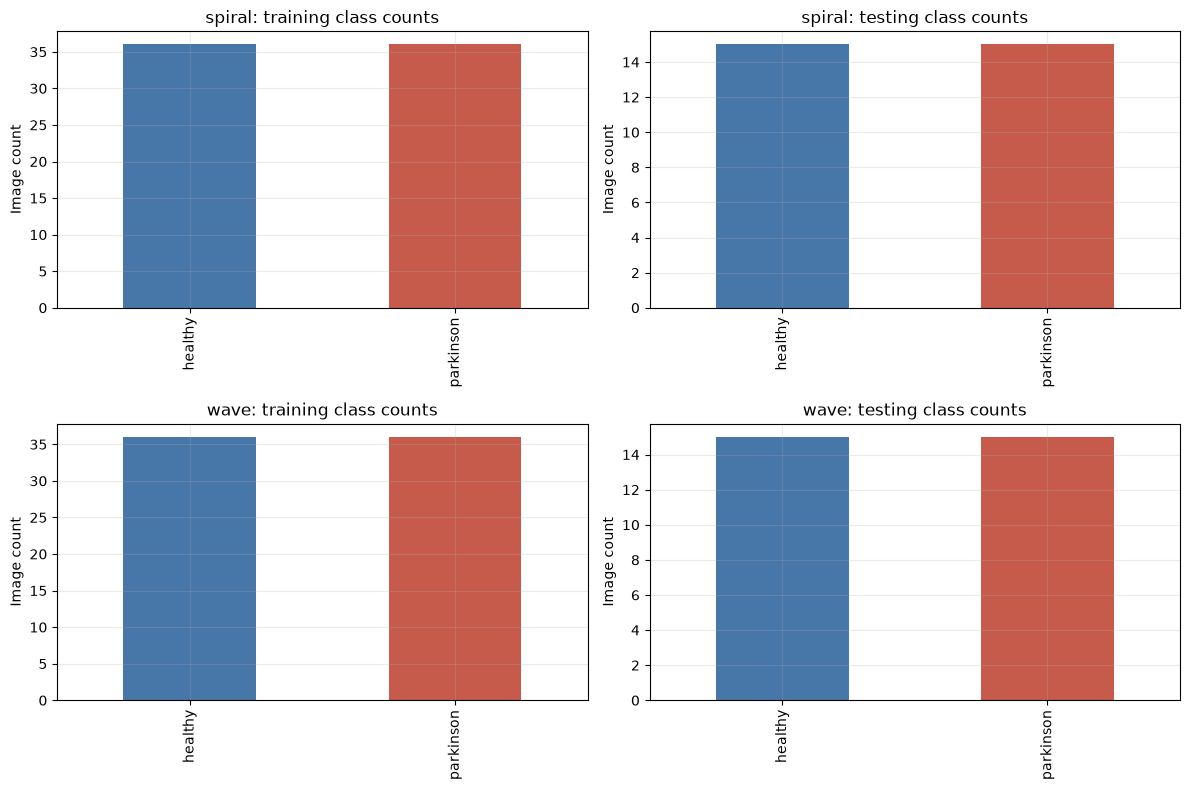

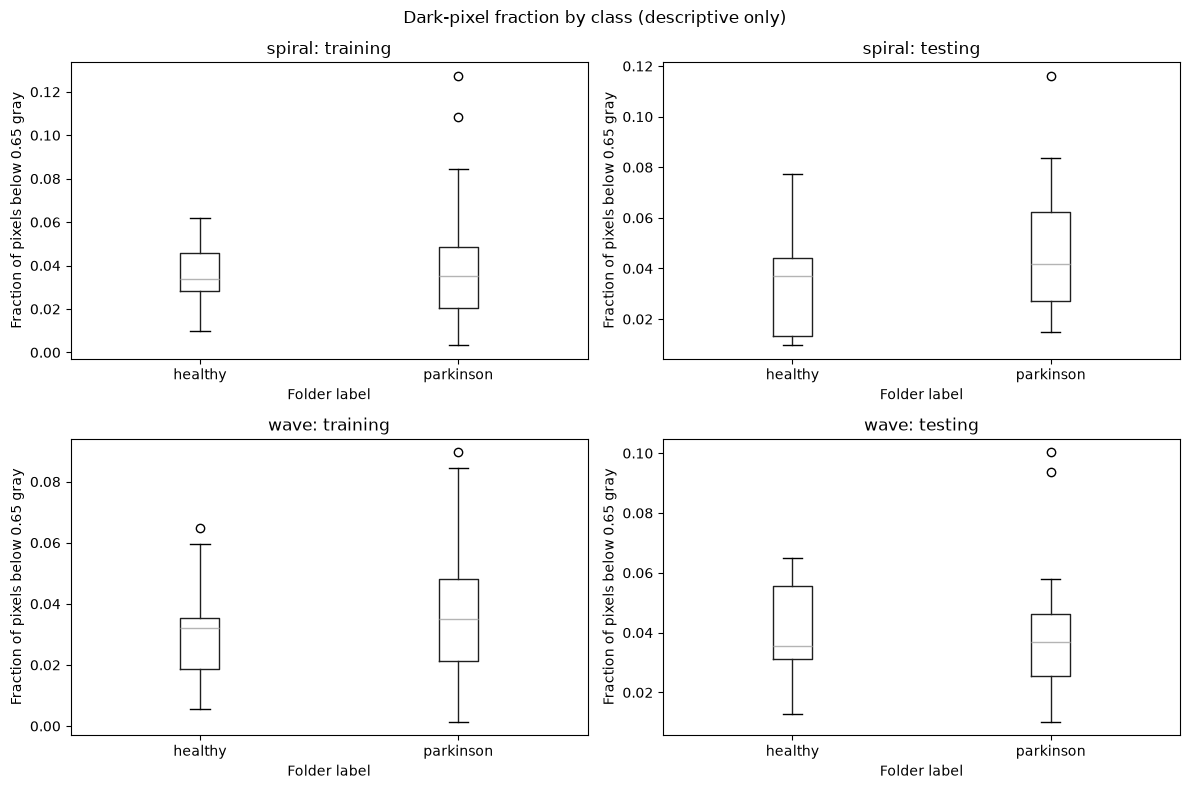

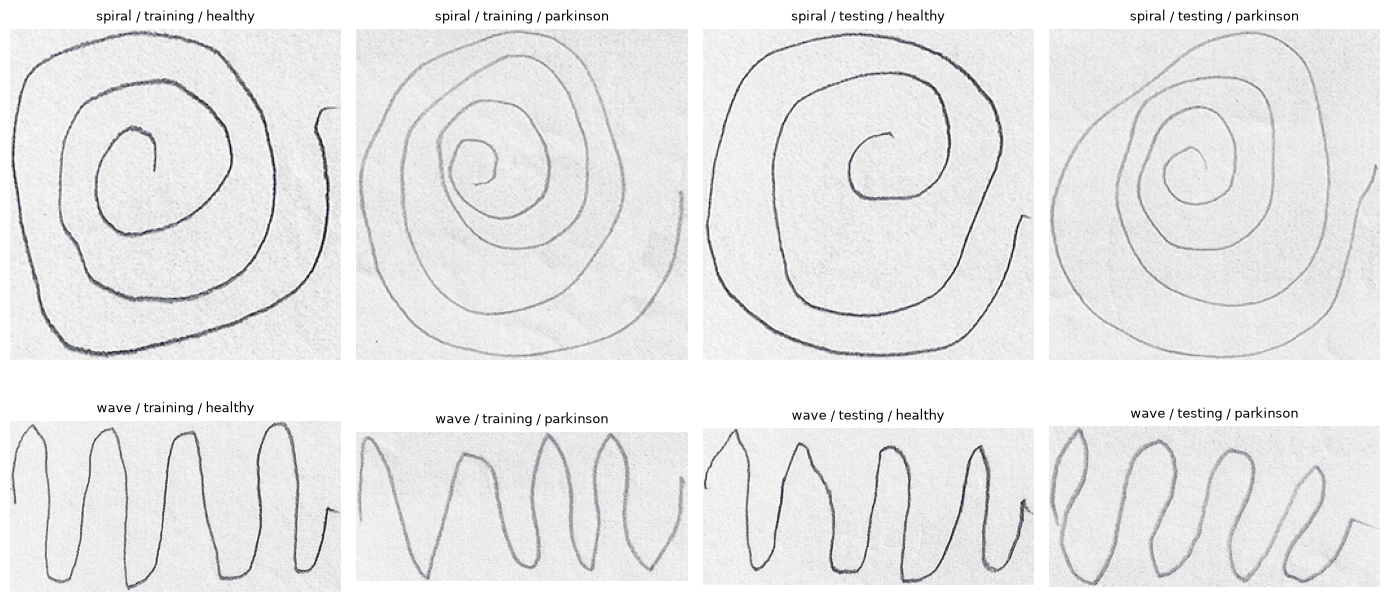

In [8]:
if not images.empty and "pixel_mean" in images:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for row_index, task in enumerate(sorted(images["task"].unique())):
        for column_index, split in enumerate(("training", "testing")):
            axis = axes[row_index, column_index]
            subset = images[(images["task"] == task) & (images["split"] == split)]
            if subset.empty:
                axis.set_visible(False)
                continue
            grouped = subset.groupby("label").size()
            grouped.plot(kind="bar", ax=axis, color=["#4776a8", "#c65b4b"][:len(grouped)])
            axis.set_title(f"{task}: {split} class counts")
            axis.set_ylabel("Image count")
            axis.set_xlabel("")
    fig.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for row_index, task in enumerate(sorted(images["task"].unique())):
        for column_index, split in enumerate(("training", "testing")):
            axis = axes[row_index, column_index]
            subset = images[(images["task"] == task) & (images["split"] == split)]
            subset.boxplot(column="dark_pixel_fraction", by="label", ax=axis, grid=False)
            axis.set_title(f"{task}: {split}")
            axis.set_xlabel("Folder label")
            axis.set_ylabel("Fraction of pixels below 0.65 gray")
    fig.suptitle("Dark-pixel fraction by class (descriptive only)")
    fig.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for row_index, task in enumerate(sorted(images["task"].unique())):
        for column_index, (split, label) in enumerate([
            ("training", "healthy"), ("training", "parkinson"),
            ("testing", "healthy"), ("testing", "parkinson"),
        ]):
            axis = axes[row_index, column_index]
            sample = images[(images["task"] == task) & (images["split"] == split) & (images["label"] == label)].sort_values("filename").iloc[0]
            with Image.open(sample["path"]) as image:
                axis.imshow(image.convert("RGB"))
            axis.set_title(f"{task} / {split} / {label}", fontsize=9)
            axis.axis("off")
    fig.tight_layout()
    plt.show()

## 4. Gait and body-motion exports

**Reasoning:** gait and motion files are large repeated-measures recordings, not necessarily one row per participant. Filenames encode `SUB##` plus `on`/`off` medication state, so random file-level splitting would leak the same person and treatment-session structure. Check file signatures before parsing by extension; this export includes `.csv`-named files that may not be text CSV.

In [10]:
import json

KINETICS_ROOT = DATA_ROOT / "Parkinson's kinetics dataset"
C3D_ROOT = KINETICS_ROOT / "C3Dfiles" / "C3Dfiles"
GAIT_ROOT = KINETICS_ROOT / "Gait cycles" / "Gait cycles"
MOTION_ROOT = DATA_ROOT / "Parkinson's motion dataset" / "UDysRS_UPDRS_Export"

# File signatures prevent trusting a misleading extension such as .csv on an OLE workbook.
def file_signature(path):
    with path.open("rb") as source:
        prefix = source.read(8)
    if prefix.startswith(bytes.fromhex("D0 CF 11 E0 A1 B1 1A E1")):
        return "OLE compound document (Excel-era binary container)"
    if prefix.startswith(b"PK\x03\x04"):
        return "ZIP-based document/workbook"
    if prefix.startswith(b"{\"") or prefix.startswith(b"[{"):
        return "JSON-like text"
    if prefix[:4] == bytes.fromhex("02 50 47 00"):
        return "C3D motion-capture binary"
    return prefix.hex(" ")

for label, root, pattern in [
    ("gait-cycle files", GAIT_ROOT, "*.csv"),
    ("C3D files", C3D_ROOT, "*.c3d"),
    ("motion export files", MOTION_ROOT, "*"),
]:
    found = sorted(path for path in root.rglob(pattern) if path.is_file()) if root.exists() else []
    print(f"{label}: {len(found):,} files")
    if found:
        display(pd.DataFrame([
            {"file": path.name, "bytes": path.stat().st_size, "signature": file_signature(path)}
            for path in found[:5]
        ]))

c3d_records = []
if C3D_ROOT.exists():
    for path in C3D_ROOT.rglob("*.c3d"):
        match = re.search(r"(SUB\d+)_(on|off)", path.as_posix(), flags=re.IGNORECASE)
        c3d_records.append({
            "subject_token_candidate": match.group(1).upper() if match else None,
            "medication_state": match.group(2).lower() if match else None,
            "recording_type": next((name for name in ("walk", "static", "tap") if name in path.stem.lower()), "other"),
            "bytes": path.stat().st_size,
        })
c3d_inventory = pd.DataFrame(c3d_records)
if not c3d_inventory.empty:
    print("C3D counts by filename-derived participant candidate, medication state, and recording type:")
    display(c3d_inventory.groupby(["subject_token_candidate", "medication_state", "recording_type"], dropna=False).size().rename("files").reset_index().head(50))
    print("Medication-state coverage by candidate participant:")
    display(c3d_inventory.groupby("subject_token_candidate")["medication_state"].nunique().value_counts().rename_axis("number_of_states").rename("participants").reset_index())

# Assessments are JSON-like; large kinematic exports are inventoried but not fully loaded into memory.
def walk_json_types(value, counts):
    if value is None:
        counts["null"] += 1
    elif isinstance(value, dict):
        counts["object"] += 1
        for child in value.values():
            walk_json_types(child, counts)
    elif isinstance(value, list):
        counts["array"] += 1
        for child in value:
            walk_json_types(child, counts)
    elif isinstance(value, bool):
        counts["boolean"] += 1
    elif isinstance(value, (int, float)):
        counts["number"] += 1
    elif isinstance(value, str):
        counts["string"] += 1

assessment_summaries = []
if MOTION_ROOT.exists():
    for path in MOTION_ROOT.glob("*.txt"):
        if path.stat().st_size > 2_000_000:
            continue
        try:
            with path.open("r", encoding="utf-8-sig") as source:
                payload = json.load(source)
        except (json.JSONDecodeError, UnicodeDecodeError):
            continue
        counts = {name: 0 for name in ("object", "array", "number", "string", "boolean", "null")}
        walk_json_types(payload, counts)
        assessment_summaries.append({"file": path.name, "top_level_type": type(payload).__name__, **counts})
print("Small JSON-like assessment exports: nested value-type counts (not a participant-level diagnosis table):")
display(pd.DataFrame(assessment_summaries))

workbook_path = KINETICS_ROOT / "PDGinfo.xlsx"
if workbook_path.exists():
    try:
        workbook = pd.ExcelFile(workbook_path)
        print("PDGinfo workbook sheet names:", workbook.sheet_names)
        for sheet_name in workbook.sheet_names:
            table = pd.read_excel(workbook_path, sheet_name=sheet_name)
            print(f"Sheet {sheet_name!r}: {table.shape[0]} rows x {table.shape[1]} columns")
            display(pd.DataFrame({
                "dtype": table.dtypes.astype(str),
                "missing_values": table.isna().sum(),
                "missing_percent": table.isna().mean().mul(100).round(2),
            }))
    except (ImportError, ValueError, OSError) as error:
        print(f"Workbook schema not inspected; install an Excel reader or verify the file: {error}")

gait-cycle files: 1,140 files


,file,bytes,signature
0,SUB01_off_walk_c7.csv,258048,OLE compound document (Excel-era binary contai...
1,SUB01_off_walk_CoM.csv,258048,OLE compound document (Excel-era binary contai...
2,SUB01_off_walk_grf.csv,51200,OLE compound document (Excel-era binary contai...
3,SUB01_off_walk_kinematics.csv,248832,OLE compound document (Excel-era binary contai...
4,SUB01_off_walk_Left_Ankle_Ang.csv,291328,OLE compound document (Excel-era binary contai...


C3D files: 935 files


,file,bytes,signature
0,SUB01_off_static_1.c3d,250080,C3D motion-capture binary
1,SUB01_off_walk_1.c3d,1095088,C3D motion-capture binary
2,SUB01_off_walk_10.c3d,889856,C3D motion-capture binary
3,SUB01_off_walk_11.c3d,835424,C3D motion-capture binary
4,SUB01_off_walk_12.c3d,2619248,C3D motion-capture binary


motion export files: 22 files


...

,number_of_states,participants
0,2,22
1,1,4


Small JSON-like assessment exports: nested value-type counts (not a participant-level diagnosis table):


,file,top_level_type,object,array,number,string,boolean,null
0,CAPSIT.txt,dict,8,825,5775,0,0,0
1,sn_numbers.txt,dict,1,0,135,0,0,0
2,TT_opt_flow_export.txt,dict,134,1064,109242,0,0,0
3,UDysRS.txt,dict,4,435,2754,0,0,0
4,UPDRS.txt,dict,19,632,2291,0,0,0


PDGinfo workbook sheet names: ['PDGinfo']
Sheet 'PDGinfo': 26 rows x 61 columns


,dtype,missing_values,missing_percent
ID,str,0,0.0
Gender,str,0,0.0
Age,int64,0,0.0
Height (cm),float64,0,0.0
Weight (kg),float64,0,0.0
...,...,...,...
OFF - Stroop-III error,object,0,0.0
OFF - TMTA time (s),object,0,0.0
OFF - TMTA error,object,0,0.0
OFF - TMTB time(s),object,0,0.0


## 5. Model evaluation: compare on validation, report test once

**Reasoning:** these are two different cohorts and targets, so compare candidate models *within* each experiment rather than pooling scores across modalities. The selection rule is validation ROC-AUC, with validation balanced accuracy as a tie-breaker; grouped-CV performance is a stability check. The test set is held back from ranking and is shown only for the already-selected candidate and a majority-class baseline.

**Metric guide:** ROC-AUC measures ranking across thresholds (0.5 is chance, 1.0 is perfect ranking), not calibrated risk. Balanced accuracy averages sensitivity and specificity, so it is less dominated by the larger class than ordinary accuracy. Sensitivity is the Parkinson's detection rate; specificity is the healthy/control rejection rate; precision is the fraction of positive predictions that are Parkinson's. F1 is the harmonic mean of precision and sensitivity. False negatives are missed cases; false positives are healthy/control cases flagged positive. A positive train-CV minus held-out-CV AUC gap is a warning sign for overfitting.

All rates are uncertain here: the held-out partitions contain very few candidate participants, so individual participants can swing the results substantially.

In [18]:
evaluation_files = {
    "spiral/wave images": PROJECT_ROOT / "results" / "drawing_training_metrics.json",
    "pen trajectories": PROJECT_ROOT / "results" / "handwriting_training_metrics.json",
}
evaluation_results = {}
comparison_rows = []
split_rows = []

for experiment, metrics_path in evaluation_files.items():
    if not metrics_path.exists():
        raise FileNotFoundError(f"Run the corresponding training pipeline first: {metrics_path}")
    with metrics_path.open("r", encoding="utf-8") as source:
        result = json.load(source)
    evaluation_results[experiment] = result

    for candidate in result["candidate_results"]:
        comparison_rows.append({
            "experiment": experiment,
            "model": candidate["model"],
            "cv_train_auc": candidate["cv_train_roc_auc_mean"],
            "cv_auc": candidate["cv_roc_auc_mean"],
            "cv_auc_sd": candidate["cv_roc_auc_std"],
            "cv_auc_gap": candidate["cv_roc_auc_gap"],
            "cv_balanced_accuracy": candidate["cv_balanced_accuracy_mean"],
            "validation_auc": candidate["validation_roc_auc"],
            "validation_balanced_accuracy": candidate["validation_balanced_accuracy"],
            "validation_sensitivity": candidate["validation_sensitivity"],
            "validation_specificity": candidate["validation_specificity"],
            "validation_precision": candidate["validation_precision"],
            "validation_f1": candidate["validation_f1"],
            "validation_false_positives": candidate["validation_false_positives"],
            "validation_false_negatives": candidate["validation_false_negatives"],
            "validation_confusion_matrix": candidate["validation_confusion_matrix"],
            "selected_on_validation": candidate["model"] == result["selected_model"],
            "best_parameters": candidate["best_params"],
        })

    baseline = result["majority_baseline_cv"]
    baseline_validation = baseline["validation_metrics"]
    baseline_confusion_key = (
        "confusion_matrix_labels_healthy_parkinson"
        if experiment == "spiral/wave images"
        else "confusion_matrix_labels_control_parkinson"
    )
    comparison_rows.append({
        "experiment": experiment,
        "model": "majority_baseline",
        "cv_train_auc": baseline["cv_train_roc_auc_mean"],
        "cv_auc": baseline["cv_roc_auc_mean"],
        "cv_auc_sd": baseline["cv_roc_auc_std"],
        "cv_auc_gap": baseline["cv_roc_auc_gap"],
        "cv_balanced_accuracy": baseline["cv_balanced_accuracy_mean"],
        "validation_auc": baseline_validation["roc_auc"],
        "validation_balanced_accuracy": baseline_validation["balanced_accuracy"],
        "validation_sensitivity": baseline_validation["sensitivity"],
        "validation_specificity": baseline_validation["specificity"],
        "validation_precision": baseline_validation["precision"],
        "validation_f1": baseline_validation["f1"],
        "validation_false_positives": baseline_validation[baseline_confusion_key][0][1],
        "validation_false_negatives": baseline_validation[baseline_confusion_key][1][0],
        "validation_confusion_matrix": "baseline reference",
        "selected_on_validation": False,
        "best_parameters": "prior probability",
    })

    for split_name, split in result["split_summary"].items():
        is_image = experiment == "spiral/wave images"
        split_rows.append({
            "experiment": experiment,
            "split": split_name,
            "observations": split["images"] if is_image else split["recording_task_samples"],
            "control_observations": split["healthy_images"] if is_image else split["control_samples"],
            "parkinson_observations": split["parkinson_images"] if is_image else split["parkinson_samples"],
            "candidate_groups": split["participant_groups"],
            "control_groups": split["healthy_groups"] if is_image else split["control_groups"],
            "parkinson_groups": split["parkinson_groups"],
        })

comparison = pd.DataFrame(comparison_rows)
split_balance = pd.DataFrame(split_rows)
print("Sample and participant-group counts by split (observations may repeat within a group):")
display(split_balance)
print("Candidate comparison. Candidates are ordered by validation ROC-AUC; selection does not use test metrics:")
display(
    comparison.sort_values(["experiment", "selected_on_validation", "validation_auc"], ascending=[True, False, False])
    [["experiment", "model", "cv_train_auc", "cv_auc", "cv_auc_sd", "cv_auc_gap",
      "validation_auc", "validation_balanced_accuracy", "validation_sensitivity",
      "validation_specificity", "validation_precision", "validation_f1",
      "validation_false_positives", "validation_false_negatives",
      "selected_on_validation", "best_parameters"]]
    .round(3)
)

Sample and participant-group counts by split (observations may repeat within a group):


,experiment,split,observations,control_observations,parkinson_observations,candidate_groups,control_groups,parkinson_groups
0,spiral/wave images,train,114,54,60,19,9,10
1,spiral/wave images,validation,42,18,24,5,3,2
2,spiral/wave images,test,48,30,18,4,1,3
3,pen trajectories,train,66,22,44,16,9,7
4,pen trajectories,validation,22,7,15,5,3,2
5,pen trajectories,test,22,8,14,4,3,1


Candidate comparison. Candidates are ordered by validation ROC-AUC; selection does not use test metrics:


,experiment,model,cv_train_auc,cv_auc,cv_auc_sd,cv_auc_gap,validation_auc,validation_balanced_accuracy,validation_sensitivity,validation_specificity,validation_precision,validation_f1,validation_false_positives,validation_false_negatives,selected_on_validation,best_parameters
4,pen trajectories,logistic_regression,0.995,0.824,0.035,0.172,1.000,1.000,1.000,1.000,1.000,1.000,0,0,True,"{""classifier__C"": 10.0}"
5,pen trajectories,rbf_svm,1.000,0.747,0.151,0.253,1.000,0.929,1.000,0.857,0.938,0.968,1,0,False,"{""classifier__C"": 10.0, ""classifier__gamma"": ""..."
6,pen trajectories,random_forest,1.000,0.796,0.066,0.204,1.000,0.857,1.000,0.714,0.882,0.938,2,0,False,"{""classifier__max_features"": 0.75, ""classifier..."
7,pen trajectories,majority_baseline,0.500,0.500,0.000,0.000,0.500,0.500,1.000,0.000,0.682,0.811,7,0,False,prior probability
0,spiral/wave images,logistic_regression,1.000,0.671,0.022,0.329,0.718,0.674,0.792,0.556,0.704,0.745,8,5,True,"{""classifier__C"": 0.01}"
2,spiral/wave images,random_forest,1.000,0.676,0.071,0.324,0.558,0.625,0.750,0.500,0.667,0.706,9,6,False,"{""classifier__max_features"": ""sqrt"", ""classifi..."
1,spiral/wave images,rbf_svm,1.000,0.652,0.049,0.348,0.500,0.465,0.542,0.389,0.542,0.542,11,11,False,"{""classifier__C"": 1.0, ""classifier__gamma"": ""s..."
3,spiral/wave images,majority_baseline,0.500,0.500,0.000,0.000,0.500,0.500,1.000,0.000,0.571,0.727,18,0,False,prior probability


In [20]:
for experiment, result in evaluation_results.items():
    selected = comparison[(comparison["experiment"] == experiment) & comparison["selected_on_validation"]]
    assert len(selected) == 1
    assert selected.iloc[0]["model"] == result["selected_model"]
    assert "test metrics are not used to select" in result["model_selection"]
    experiment_splits = split_balance[split_balance["experiment"] == experiment]
    assert (experiment_splits[["control_groups", "parkinson_groups"]] > 0).all().all()
    confusion_key = (
        "confusion_matrix_labels_healthy_parkinson"
        if experiment == "spiral/wave images"
        else "confusion_matrix_labels_control_parkinson"
    )
    for metrics in (result["majority_baseline_test_metrics"], result["test_metrics"]):
        assert np.asarray(metrics[confusion_key]).sum() == metrics.get("n_images", metrics.get("n_recording_task_samples"))
print("Evaluation checks passed: one validation-selected candidate per cohort, both classes represented in every split, and test confusion counts match test sample totals.")

Evaluation checks passed: one validation-selected candidate per cohort, both classes represented in every split, and test confusion counts match test sample totals.


### Visual diagnostics and held-out errors

**Reasoning:** CV versus validation bars expose unstable rankings and train/CV gaps; class-group bars show the actual independent-unit imbalance; confusion matrices make the selected model's false positives and false negatives concrete. Test plots include only the validation-selected model and a majority baseline, not every unselected candidate.

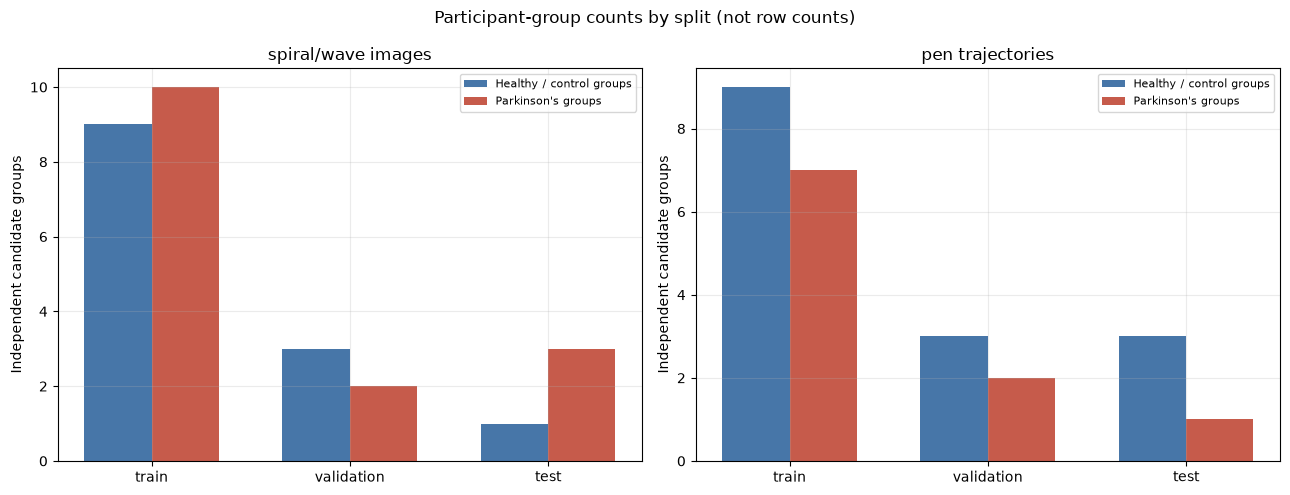

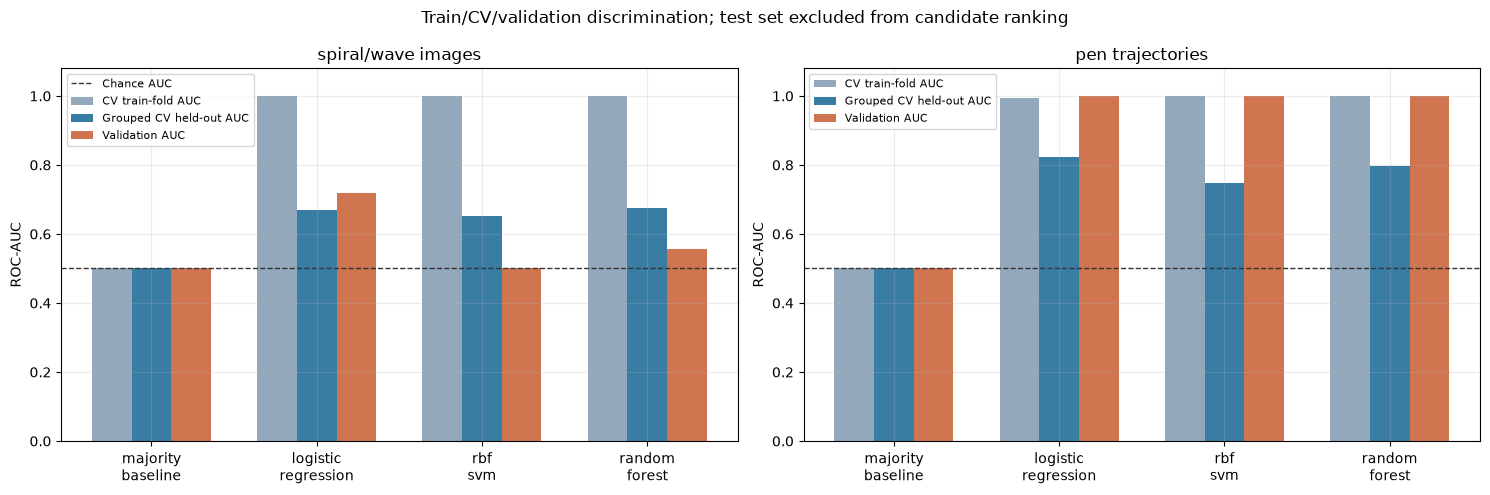

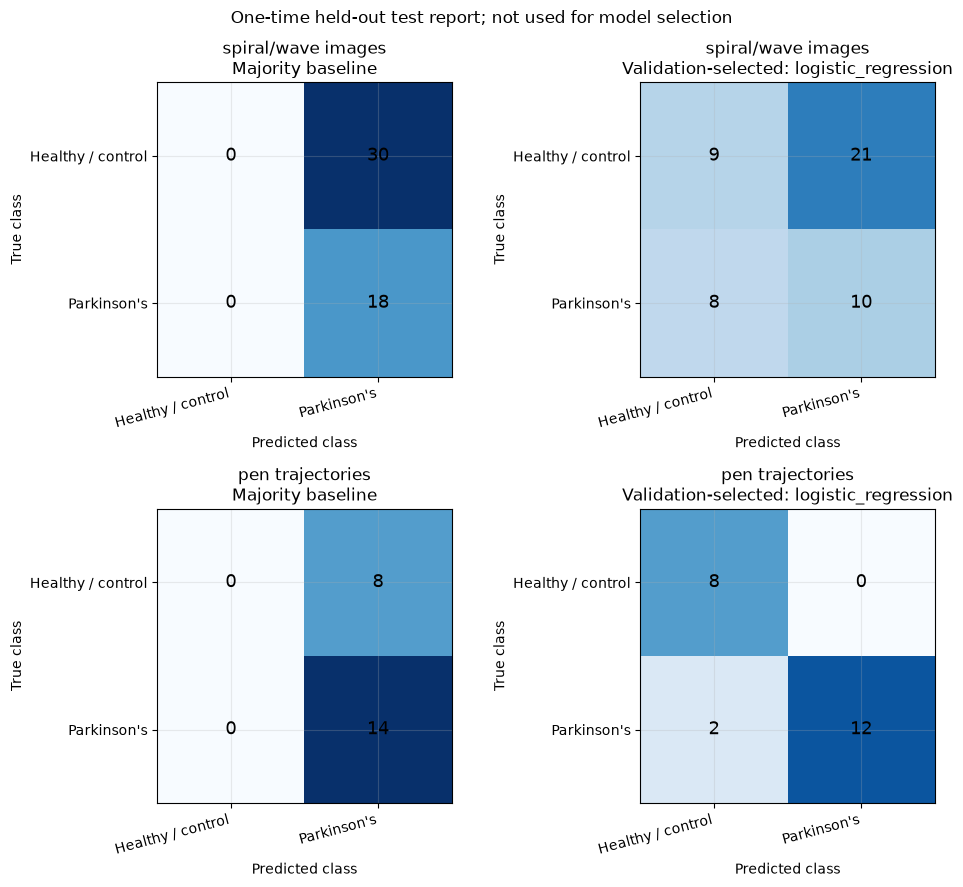

Held-out test metrics for baseline and preselected candidate only:


,experiment,model,test_observations,test_roc_auc,test_balanced_accuracy,test_sensitivity,test_specificity,test_precision,test_f1,false_positives,false_negatives
0,spiral/wave images,Majority baseline,48,0.500,0.500,1.000,0.0,0.375,0.545,30,0
1,spiral/wave images,Validation-selected: logistic_regression,48,0.494,0.428,0.556,0.3,0.323,0.408,21,8
2,pen trajectories,Majority baseline,22,0.500,0.500,1.000,0.0,0.636,0.778,8,0
3,pen trajectories,Validation-selected: logistic_regression,22,0.920,0.929,0.857,1.0,1.000,0.923,0,2


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, experiment in zip(axes, evaluation_files):
    subset = split_balance[split_balance["experiment"] == experiment].set_index("split").loc[["train", "validation", "test"]]
    positions = np.arange(len(subset))
    width = 0.34
    axis.bar(positions - width / 2, subset["control_groups"], width, label="Healthy / control groups", color="#4776a8")
    axis.bar(positions + width / 2, subset["parkinson_groups"], width, label="Parkinson's groups", color="#c65b4b")
    axis.set_xticks(positions, subset.index)
    axis.set_ylabel("Independent candidate groups")
    axis.set_title(experiment)
    axis.legend(fontsize=8)
fig.suptitle("Participant-group counts by split (not row counts)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for axis, experiment in zip(axes, evaluation_files):
    subset = comparison[comparison["experiment"] == experiment].set_index("model")
    order = [name for name in ("majority_baseline", "logistic_regression", "rbf_svm", "random_forest") if name in subset.index]
    subset = subset.loc[order]
    positions = np.arange(len(subset))
    width = 0.24
    axis.bar(positions - width, subset["cv_train_auc"], width, label="CV train-fold AUC", color="#94a8bc")
    axis.bar(positions, subset["cv_auc"], width, label="Grouped CV held-out AUC", color="#397da5")
    axis.bar(positions + width, subset["validation_auc"], width, label="Validation AUC", color="#cf7651")
    axis.axhline(0.5, color="#333333", linestyle="--", linewidth=1, label="Chance AUC" if axis is axes[0] else None)
    axis.set_xticks(positions, [name.replace("_", "\n") for name in order])
    axis.set_ylim(0, 1.08)
    axis.set_ylabel("ROC-AUC")
    axis.set_title(experiment)
    axis.legend(fontsize=8)
fig.suptitle("Train/CV/validation discrimination; test set excluded from candidate ranking")
fig.tight_layout()
plt.show()

heldout_rows = []
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for row_index, experiment in enumerate(evaluation_files):
    result = evaluation_results[experiment]
    confusion_key = (
        "confusion_matrix_labels_healthy_parkinson"
        if experiment == "spiral/wave images"
        else "confusion_matrix_labels_control_parkinson"
    )
    class_names = ["Healthy / control", "Parkinson's"]
    model_metrics = [
        ("Majority baseline", result["majority_baseline_test_metrics"]),
        (f"Validation-selected: {result['selected_model']}", result["test_metrics"]),
    ]
    row_max = max(max(max(matrix_row) for matrix_row in metrics[confusion_key]) for _, metrics in model_metrics)
    for column_index, (model_name, metrics) in enumerate(model_metrics):
        matrix = np.asarray(metrics[confusion_key], dtype=int)
        axis = axes[row_index, column_index]
        axis.imshow(matrix, cmap="Blues", vmin=0, vmax=max(row_max, 1))
        for true_index in range(2):
            for predicted_index in range(2):
                axis.text(predicted_index, true_index, str(matrix[true_index, predicted_index]),
                          ha="center", va="center", color="black", fontsize=13)
        axis.set_xticks([0, 1], class_names, rotation=15, ha="right")
        axis.set_yticks([0, 1], class_names)
        axis.set_xlabel("Predicted class")
        axis.set_ylabel("True class")
        axis.set_title(f"{experiment}\n{model_name}")
        heldout_rows.append({
            "experiment": experiment,
            "model": model_name,
            "test_observations": metrics["n_images"] if experiment == "spiral/wave images" else metrics["n_recording_task_samples"],
            "test_roc_auc": metrics["roc_auc"],
            "test_balanced_accuracy": metrics["balanced_accuracy"],
            "test_sensitivity": metrics["sensitivity"],
            "test_specificity": metrics["specificity"],
            "test_precision": metrics["precision"],
            "test_f1": metrics["f1"],
            "false_positives": int(matrix[0, 1]),
            "false_negatives": int(matrix[1, 0]),
        })
fig.suptitle("One-time held-out test report; not used for model selection")
fig.tight_layout()
plt.show()
print("Held-out test metrics for baseline and preselected candidate only:")
display(pd.DataFrame(heldout_rows).round(3))

### Reading this run and its limits

- **Spiral/wave images:** logistic regression was selected on validation (AUC 0.718; balanced accuracy 0.674). Its held-out AUC was 0.494 and balanced accuracy 0.428, below the majority baseline's 0.500 balanced accuracy. On 48 images, it produced 21 false positives and 8 false negatives. The test split has only four candidate groups: one healthy and three Parkinson's.
- **Pen trajectories:** logistic regression was selected on validation. Grouped-CV AUC was 0.824, with a 0.172 train-versus-held-out CV AUC gap; validation AUC was 1.000 on five groups. Held-out AUC was 0.920 and balanced accuracy 0.929, with two false negatives and no false positives among 22 task samples. However, the test split has only four groups, including **one Parkinson's group**; repeated task samples from that group are correlated, not 14 independent patients.
- **Class balance:** observation counts and group counts differ. The image test has 30 healthy versus 18 Parkinson's images but only 1 versus 3 groups; the trajectory test has 8 control versus 14 Parkinson's task samples but 3 versus 1 groups. Majority baselines reach sensitivity 1.0 by predicting Parkinson's for every observation, while specificity is 0.0, illustrating why sensitivity or accuracy alone is insufficient.
- **Overfitting and uncertainty:** candidate train-fold AUC is 0.97-1.00 while held-out grouped-CV AUC is lower. This is a substantial generalization gap. Only three grouped CV folds and a handful of validation/test participants are available; no confidence intervals or stable population estimates are justified.
- **Scope:** labels are known case/control, not future onset; the datasets are not participant-linked across modalities; filename-derived groups need verification. These results are not calibrated individual risk estimates, a prospective early-detection test, or clinical evidence. A credible next evaluation needs a larger participant-level cohort, externally held-out participants/sites, verified IDs, prospective at-risk follow-up, and matched touchscreen tapping/body-motion data.